<a href="https://colab.research.google.com/github/kaixing189/MSSP607/blob/main/CA_Congressional_Districts_Visualization_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# MSSP607 Participation Activity
## California Congressional Districts and Population Visualization

**Student:** Kai Xing



## 1. Import libraries

In [1]:

import io
import requests
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import folium

from pathlib import Path
from folium.plugins import HeatMap

pd.set_option("display.max_columns", None)



## 2. Load the CSV and GeoJSON



In [2]:

CSV_CANDIDATES = [
    Path("/content/MSSP607/data/CA_Legislative_Districts.csv"),
    Path("/content/CA_Legislative_Districts.csv"),
    Path("/mnt/data/CA_Legislative_Districts.csv"),
]

GEO_CANDIDATES = [
    Path("/content/MSSP607/data/california-congressional-districts.geojson"),
    Path("/content/california-congressional-districts.geojson"),
    Path("/mnt/data/california-congressional-districts.geojson"),
]

CSV_GITHUB = "https://raw.githubusercontent.com/kaixing189/MSSP607/main/data/CA_Legislative_Districts.csv"
GEO_GITHUB = "https://raw.githubusercontent.com/kaixing189/MSSP607/main/data/california-congressional-districts.geojson"

csv_local = next((p for p in CSV_CANDIDATES if p.exists()), None)
geo_local = next((p for p in GEO_CANDIDATES if p.exists()), None)

if csv_local is not None:
    population = pd.read_csv(csv_local)
    print("CSV loaded from:", csv_local)
else:
    try:
        population = pd.read_csv(CSV_GITHUB)
        print("CSV loaded from GitHub.")
    except Exception as e:
        raise FileNotFoundError(
            "CA_Legislative_Districts.csv was not found. "
            "Upload it to Colab or save it in MSSP607/data/."
        ) from e

if geo_local is not None:
    districts = gpd.read_file(geo_local)
    print("GeoJSON loaded from:", geo_local)
else:
    try:
        districts = gpd.read_file(GEO_GITHUB)
        print("GeoJSON loaded from GitHub.")
    except Exception as e:
        raise FileNotFoundError(
            "california-congressional-districts.geojson was not found. "
            "Upload it to Colab or save it in MSSP607/data/."
        ) from e

print("\nCSV shape:", population.shape)
print("GeoJSON shape:", districts.shape)

display(population.head())
display(districts.head())


CSV loaded from GitHub.
GeoJSON loaded from GitHub.

CSV shape: (52, 25)
GeoJSON shape: (53, 4)


,OBJECTID,ID,AREA,DISTRICT,MEMBERS,NAME,POPULATION,CVAP_19,HSP_CVAP_1,DOJ_NH_BLK,DOJ_NH_ASN,NH_WHT_CVA,IDEAL_VALU,DEVIATION,F_DEVIATIO,MULTIPLE_F,F_CVAP_19,F_HSP_CVAP,F_DOJ_NH_B,F_DOJ_NH_A,F_NH_WHT_C,DISTRICT_L,DISTRICT_N,SHAPE_Length,SHAPE_Area
0,1,1,27014.63,1,1,MTCAP,760066,549203,77031,10923,26100,412285,760066,0,0,1|0,0.7226,0.1403,0.0199,0.0475,0.7507,1|0%,1,2.633906e+06,1.222952e+11
1,2,2,560.65,10,1,STANI,760066,503249,67160,26317,86189,313011,760066,0,0,10|0,0.6621,0.1335,0.0523,0.1713,0.6220,10|0%,10,3.582890e+05,2.336909e+09
2,3,3,226.43,11,1,COCO,760067,568460,61171,33907,179614,284594,760066,1,0,11|1,0.7479,0.1076,0.0596,0.3160,0.5006,11|0%,11,2.111932e+05,9.404054e+08
3,4,4,141.25,12,1,SF,760065,510978,74038,101894,109309,213023,760066,-1,0,12|-1,0.6723,0.1449,0.1994,0.2139,0.4169,12|-0%,12,1.246786e+05,5.869476e+08
4,5,5,6346.92,13,1,OKLND,760065,393416,197645,16042,24438,145877,760066,-1,0,13|-1,0.5176,0.5024,0.0408,0.0621,0.3708,13|-0%,13,1.186868e+06,2.578115e+10


,Name,description,descriptio,geometry
0,01,None,,"MULTIPOLYGON (((-120.07192 41.99495, -120.0010..."
1,02,None,,"MULTIPOLYGON (((-123.69821 41.81719, -123.6967..."
2,03,None,,"MULTIPOLYGON (((-121.667 39.30511, -121.63015 ..."
3,04,None,,"MULTIPOLYGON (((-120.37731 37.61679, -120.3823..."
4,05,None,,"MULTIPOLYGON (((-122.16384 38.64288, -122.1659..."



## 3. Prepare district identifiers


In [3]:

population["district_id"] = pd.to_numeric(
    population["DISTRICT_N"], errors="coerce"
).astype("Int64")

districts["district_id"] = pd.to_numeric(
    districts["Name"], errors="coerce"
).astype("Int64")

print("Population district count:", population["district_id"].nunique())
print("Population district range:",
      population["district_id"].min(),
      "to",
      population["district_id"].max())

print("GeoJSON district count:", districts["district_id"].nunique())
print("GeoJSON district range:",
      districts["district_id"].min(),
      "to",
      districts["district_id"].max())

display(
    population[
        ["district_id", "POPULATION", "NAME", "AREA"]
    ].head()
)


Population district count: 52
Population district range: 1 to 52
GeoJSON district count: 53
GeoJSON district range: 1 to 53


,district_id,POPULATION,NAME,AREA
0,1,760066,MTCAP,27014.63
1,10,760066,STANI,560.65
2,11,760067,COCO,226.43
3,12,760065,SF,141.25
4,13,760065,OKLND,6346.92



### Data-vintage check




In [4]:

csv_ids = set(population["district_id"].dropna().astype(int))
geo_ids = set(districts["district_id"].dropna().astype(int))

print("Districts only in CSV:", sorted(csv_ids - geo_ids))
print("Districts only in GeoJSON:", sorted(geo_ids - csv_ids))


Districts only in CSV: []
Districts only in GeoJSON: [53]


## 4. Visualize California Congressional District boundaries

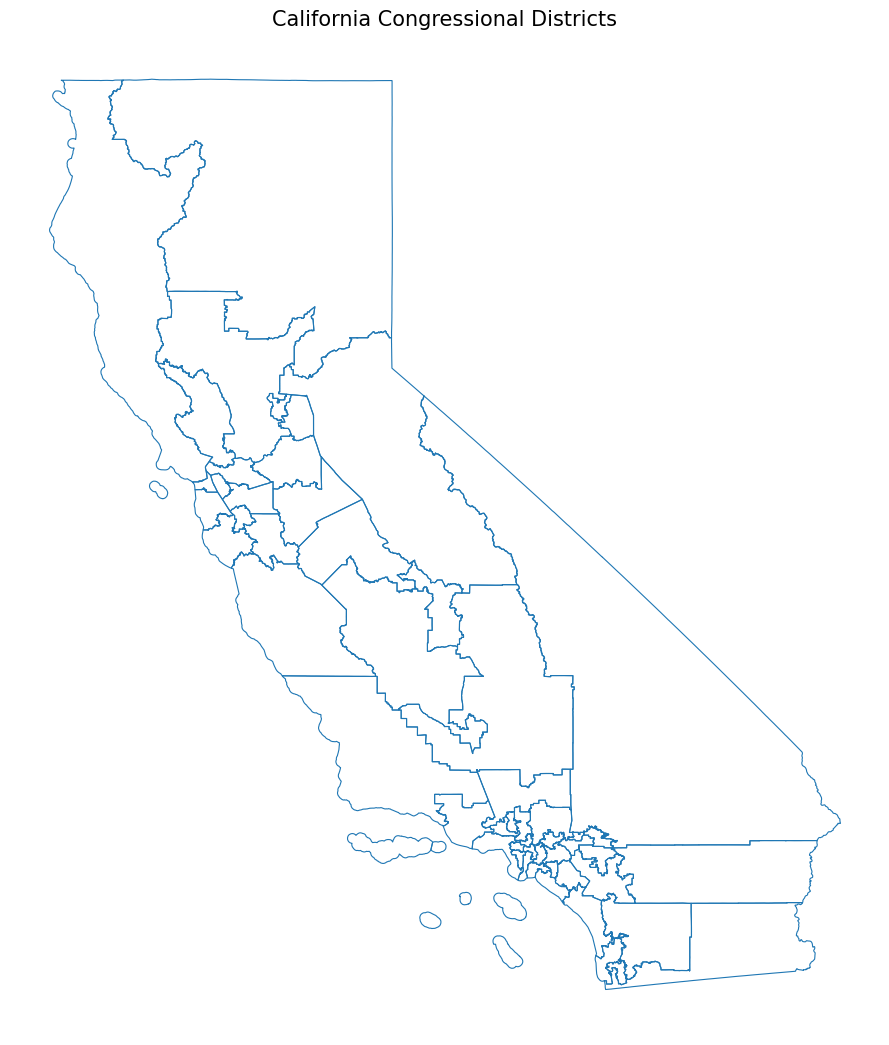

In [5]:

fig, ax = plt.subplots(figsize=(9, 11))

districts.boundary.plot(
    ax=ax,
    linewidth=0.8
)

ax.set_title("California Congressional Districts", fontsize=15)
ax.set_axis_off()

plt.tight_layout()
plt.show()



The map above shows the congressional district boundaries contained in the GeoJSON file.



## 5. Overlay population on the congressional district geometries



In [6]:

pop_keep = population[
    ["district_id", "POPULATION", "NAME", "AREA"]
].copy()

district_pop = districts.merge(
    pop_keep,
    on="district_id",
    how="left"
)

display(
    district_pop[
        ["district_id", "POPULATION", "NAME", "AREA"]
    ].head(10)
)

print("Matched districts:", district_pop["POPULATION"].notna().sum())
print("Unmatched geometries:", district_pop["POPULATION"].isna().sum())

display(
    district_pop.loc[
        district_pop["POPULATION"].isna(),
        ["district_id", "Name"]
    ]
)


,district_id,POPULATION,NAME,AREA
0,1,760066.0,MTCAP,27014.63
1,2,760067.0,NOCST,14613.65
2,3,760065.0,YUBA,22035.87
3,4,760065.0,FTHLL,3923.91
4,5,760065.0,NEBAY,9962.22
5,6,760066.0,SAC,254.07
6,7,760066.0,SACCO,706.51
7,8,760065.0,INMSB,614.83
8,9,760066.0,SNJOA,1382.65
9,10,760066.0,STANI,560.65


Matched districts: 52
Unmatched geometries: 1


,district_id,Name
52,53,53



## 6. Population choropleth




,POPULATION
count,52.000000
mean,760066.096154
std,0.773574
min,760065.000000
25%,760065.750000
50%,760066.000000
75%,760067.000000
max,760067.000000


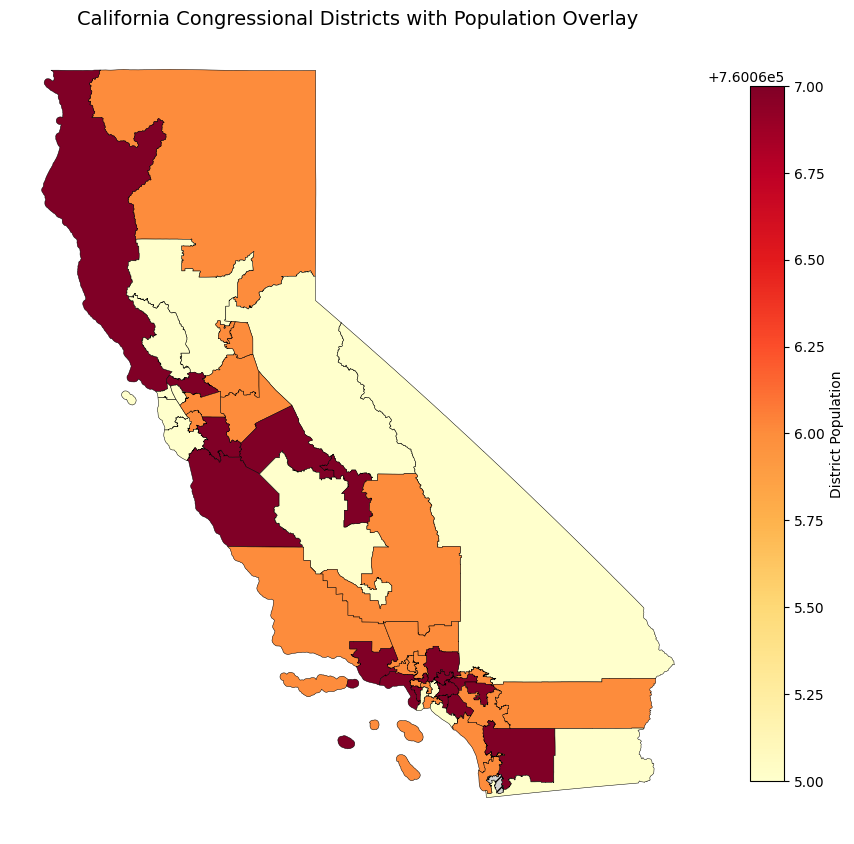

In [7]:

display(population["POPULATION"].describe())

fig, ax = plt.subplots(figsize=(9, 11))

district_pop.plot(
    column="POPULATION",
    ax=ax,
    legend=True,
    cmap="YlOrRd",
    edgecolor="black",
    linewidth=0.35,
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "black",
        "hatch": "///",
        "label": "No matching population"
    },
    legend_kwds={
        "label": "District Population",
        "shrink": 0.65
    }
)

ax.set_title(
    "California Congressional Districts with Population Overlay",
    fontsize=14
)
ax.set_axis_off()

plt.tight_layout()
plt.show()


## 7. Label congressional districts

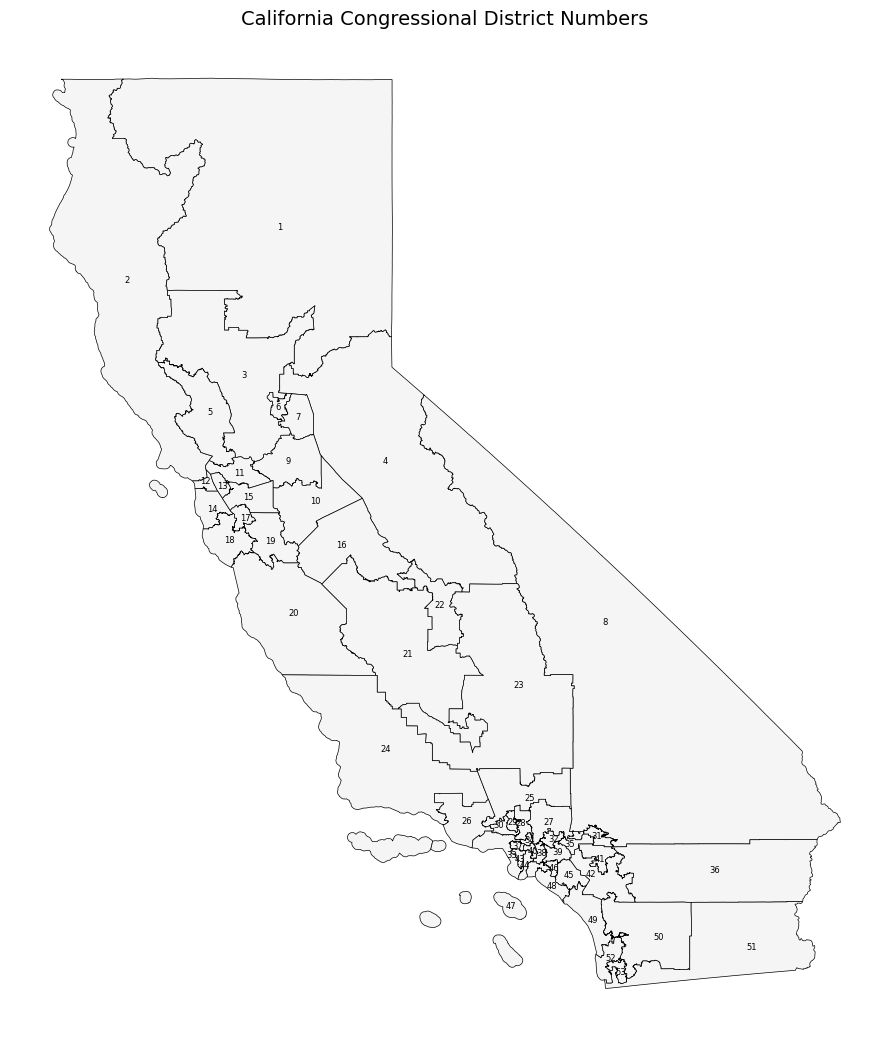

In [8]:

# Compute representative points using a California projected CRS.
district_projected = district_pop.to_crs(epsg=3310)
label_points_projected = district_projected.representative_point()
label_points = gpd.GeoSeries(
    label_points_projected,
    crs=3310
).to_crs(epsg=4326)

fig, ax = plt.subplots(figsize=(9, 11))

district_pop.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="black",
    linewidth=0.5
)

for district_id, point in zip(
    district_pop["district_id"],
    label_points
):
    ax.text(
        point.x,
        point.y,
        str(int(district_id)),
        fontsize=6,
        ha="center",
        va="center"
    )

ax.set_title("California Congressional District Numbers", fontsize=14)
ax.set_axis_off()

plt.tight_layout()
plt.show()



## 8. Create a statewide population heatmap



In [9]:

matched = district_pop.dropna(subset=["POPULATION"]).copy()

matched_projected = matched.to_crs(epsg=3310)
rep_points_projected = matched_projected.representative_point()
rep_points = gpd.GeoSeries(
    rep_points_projected,
    crs=3310
).to_crs(epsg=4326)

heat_data = [
    [point.y, point.x, float(pop)]
    for point, pop in zip(rep_points, matched["POPULATION"])
]

ca_heatmap = folium.Map(
    location=[37.2, -119.7],
    zoom_start=5,
    tiles="CartoDB positron"
)

folium.GeoJson(
    districts.to_json(),
    name="Congressional District Boundaries",
    style_function=lambda feature: {
        "fillColor": "transparent",
        "color": "black",
        "weight": 0.7
    }
).add_to(ca_heatmap)

max_pop = matched["POPULATION"].max()
scaled_heat_data = [
    [lat, lon, weight / max_pop]
    for lat, lon, weight in heat_data
]

HeatMap(
    scaled_heat_data,
    radius=30,
    blur=25,
    min_opacity=0.30,
    name="Population Heatmap"
).add_to(ca_heatmap)

folium.LayerControl().add_to(ca_heatmap)

ca_heatmap


/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore



## 9. Interactive district population map


In [10]:

interactive = folium.Map(
    location=[37.2, -119.7],
    zoom_start=5,
    tiles="CartoDB positron"
)

folium.GeoJson(
    district_pop.to_json(),
    style_function=lambda feature: {
        "fillColor": "#3186cc"
        if feature["properties"].get("POPULATION") is not None
        else "#cccccc",
        "color": "black",
        "weight": 0.6,
        "fillOpacity": 0.35
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["district_id", "POPULATION"],
        aliases=["District:", "Population:"],
        localize=True
    )
).add_to(interactive)

interactive


/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore



## 10. Summary

The GeoJSON contains 53 congressional district geometries. The CSV contains 52 population records, with district population values ranging only from about 760,065 to 760,067.

The notebook creates:
- a congressional district boundary map,
- a population choropleth,
- a district-number map,
- a statewide population heatmap, and
- an interactive district population map.

The main limitation is the apparent redistricting-vintage mismatch between the two source files.


## 11. Final verification

In [11]:

assert population.shape[0] == 52
assert population["district_id"].nunique() == 52
assert districts.shape[0] == 53
assert districts["district_id"].nunique() == 53
assert district_pop["POPULATION"].notna().sum() == 52
assert district_pop["POPULATION"].isna().sum() == 1
assert 53 in set(
    district_pop.loc[
        district_pop["POPULATION"].isna(),
        "district_id"
    ].astype(int)
)

print("All required geospatial results verified successfully.")


All required geospatial results verified successfully.
